# Ejercicio 7: Análisis Sociodemográfico y Reporte de Clustering

Se debe realizar una interpretación y reporte de comunicación enfocado en características sociodemográficas

1. Describir características sociodemográficas comunes de cada cluster (income, age, sex).
2. Generar visualizaciones sociodemográficas (gráficos comparativos, mapas de calor, etc.).
3. Redactar informe con metodología, resultados y conclusiones sociodemográficas.

**Informe completo disponible en:** `Docs/ejercicio7.md`

## Paso 1: Carga de datos y replicación de clusters del Ejercicio 6

**Nota:** Replicamos la configuración exacta del Ejercicio 6 para mantener consistencia.
- Muestra: 5000 registros (random_state=42)
- K-means: k óptimo según Ejercicio 6
- Enfoque: ANÁLISIS SOCIODEMOGRÁFICO y VISUALIZACIÓN (income, age, sex)


In [1]:
import sys
sys.path.append('..')
from utils import cargar_dataset_adult

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

# Cargar dataset
df = cargar_dataset_adult()

# IMPORTANTE: Tomar la MISMA muestra que en el Ejercicio 6 (random_state=42)
sample_size = 5000
df = df.sample(n=sample_size, random_state=42).copy()

print("="*60)
print("EJERCICIO 7: ANÁLISIS SOCIODEMOGRÁFICO Y VISUALIZACIÓN DE CLUSTERS")
print("="*60)
print(f"\n✓ Usando la MISMA muestra del Ejercicio 6:")
print(f"  • Tamaño: {sample_size:,} observaciones")
print(f"  • Random state: 42")
print(f"  • Enfoque: Análisis sociodemográfico (income, age, sex)")


EJERCICIO 7: ANÁLISIS SOCIODEMOGRÁFICO Y VISUALIZACIÓN DE CLUSTERS

✓ Usando la MISMA muestra del Ejercicio 6:
  • Tamaño: 5,000 observaciones
  • Random state: 42
  • Enfoque: Análisis sociodemográfico (income, age, sex)


## Paso 2: Replicar clustering del Ejercicio 6 (K-means)

**Configuración del Ejercicio 6:**
- Algoritmo: K-means
- Variables: numéricas (age, education-num, capital-gain, capital-loss, hours-per-week)
- K óptimo: Determinado por Silhouette en Ejercicio 6
- Objetivo aquí: ANÁLISIS SOCIODEMOGRÁFICO y VISUALIZACIÓN (income, age, sex)


In [2]:
# ============================================================================
# REPLICANDO CONFIGURACIÓN DEL EJERCICIO 6
# ============================================================================
# Usamos EXACTAMENTE la misma configuración para obtener los mismos clusters
# que fueron evaluados en el Ejercicio 6.
# ============================================================================

# Variables numéricas (igual que Ejercicio 6)
numeric_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

# Normalizar datos
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df[numeric_cols])

# Aplicar K-means con el k óptimo del Ejercicio 6
# (según Silhouette, el k óptimo fue 3 en el Ejercicio 6)
k_optimo_kmeans = 3  # ← Del Ejercicio 6

kmeans = KMeans(n_clusters=k_optimo_kmeans, random_state=42, n_init=10)
df['cluster_kmeans'] = kmeans.fit_predict(df_scaled)

print("\n" + "-"*60)
print("CLUSTERING K-MEANS APLICADO")
print("-"*60)
print(f"\n✓ Configuración:")
print(f"  • Algoritmo: K-means")
print(f"  • Variables: {len(numeric_cols)} numéricas")
print(f"  • K óptimo: {k_optimo_kmeans} (del Ejercicio 6)")
print(f"\n✓ Distribución de clusters:")
cluster_counts = df['cluster_kmeans'].value_counts().sort_index()
for cluster_id, count in cluster_counts.items():
    pct = count / len(df) * 100
    print(f"  • Cluster {cluster_id}: {count:,} observaciones ({pct:.1f}%)")



------------------------------------------------------------
CLUSTERING K-MEANS APLICADO
------------------------------------------------------------

✓ Configuración:
  • Algoritmo: K-means
  • Variables: 5 numéricas
  • K óptimo: 3 (del Ejercicio 6)

✓ Distribución de clusters:
  • Cluster 0: 4,762 observaciones (95.2%)
  • Cluster 1: 212 observaciones (4.2%)
  • Cluster 2: 26 observaciones (0.5%)


## Paso 3: Análisis sociodemográfico por cluster

**Objetivo:** Describir las características sociodemográficas (income, age, sex) dentro de cada cluster para entender patrones de ingresos y diferencias sociodemográficas.


In [3]:
# ============================================================================
# ANÁLISIS SOCIODEMOGRÁFICO POR CLUSTER
# ============================================================================

print("="*70)
print("ANÁLISIS SOCIODEMOGRÁFICO POR CLUSTER")
print("="*70)

# Variables sociodemográficas clave
sociodemographic_vars = ['income', 'age', 'sex']

# Análisis de características sociodemográficas por cluster
print("\n1. ESTADÍSTICAS SOCIODEMOGRÁFICAS POR CLUSTER:")
print("="*60)

for cluster_id in sorted(df['cluster_kmeans'].unique()):
    cluster_data = df[df['cluster_kmeans'] == cluster_id]
    print(f"\n--- CLUSTER {cluster_id} ---")
    print(f"Tamaño: {len(cluster_data):,} personas ({len(cluster_data)/len(df)*100:.1f}%)")
    
    # Análisis de ingresos
    income_dist = cluster_data['income'].value_counts()
    high_income_pct = (income_dist.get('>50K', 0) / len(cluster_data)) * 100
    print(f"Ingresos altos (>$50K): {high_income_pct:.1f}%")
    
    # Análisis de edad
    age_stats = cluster_data['age'].describe()
    print(f"Edad promedio: {age_stats['mean']:.1f} años")
    print(f"Rango de edad: {age_stats['min']:.0f}-{age_stats['max']:.0f} años")
    
    # Análisis de género
    gender_dist = cluster_data['sex'].value_counts()
    male_pct = (gender_dist.get('Male', 0) / len(cluster_data)) * 100
    female_pct = (gender_dist.get('Female', 0) / len(cluster_data)) * 100
    print(f"Género: {male_pct:.1f}% masculino, {female_pct:.1f}% femenino")

# Análisis comparativo de ingresos
print("\n" + "="*60)
print("2. ANÁLISIS COMPARATIVO DE INGRESOS POR CLUSTER:")
print("="*60)

income_by_cluster = pd.crosstab(df['cluster_kmeans'], df['income'], normalize='index') * 100
print("\nDistribución de ingresos por cluster (%):")
print(income_by_cluster.round(2))

# Identificar cluster con mayor proporción de ingresos altos
high_income_clusters = income_by_cluster['>50K'].sort_values(ascending=False)
print(f"\nClusters ordenados por % de ingresos altos:")
for cluster, pct in high_income_clusters.items():
    print(f"Cluster {cluster}: {pct:.1f}% ingresos altos")

# Análisis de edad por cluster
print("\n" + "="*60)
print("3. ANÁLISIS DE EDAD POR CLUSTER:")
print("="*60)

age_by_cluster = df.groupby('cluster_kmeans')['age'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print("\nEstadísticas de edad por cluster:")
print(age_by_cluster.round(2))

# Análisis de género por cluster
print("\n" + "="*60)
print("4. ANÁLISIS DE GÉNERO POR CLUSTER:")
print("="*60)

gender_by_cluster = pd.crosstab(df['cluster_kmeans'], df['sex'], normalize='index') * 100
print("\nDistribución de género por cluster (%):")
print(gender_by_cluster.round(2))


ANÁLISIS SOCIODEMOGRÁFICO POR CLUSTER

1. ESTADÍSTICAS SOCIODEMOGRÁFICAS POR CLUSTER:

--- CLUSTER 0 ---
Tamaño: 4,762 personas (95.2%)
Ingresos altos (>$50K): 22.3%
Edad promedio: 38.3 años
Rango de edad: 17-90 años
Género: 66.0% masculino, 34.0% femenino

--- CLUSTER 1 ---
Tamaño: 212 personas (4.2%)
Ingresos altos (>$50K): 43.9%
Edad promedio: 41.2 años
Rango de edad: 18-77 años
Género: 79.7% masculino, 20.3% femenino

--- CLUSTER 2 ---
Tamaño: 26 personas (0.5%)
Ingresos altos (>$50K): 100.0%
Edad promedio: 44.7 años
Rango de edad: 22-61 años
Género: 80.8% masculino, 19.2% femenino

2. ANÁLISIS COMPARATIVO DE INGRESOS POR CLUSTER:

Distribución de ingresos por cluster (%):
income          <=50K    >50K
cluster_kmeans               
0               77.70   22.30
1               56.13   43.87
2                0.00  100.00

Clusters ordenados por % de ingresos altos:
Cluster 2: 100.0% ingresos altos
Cluster 1: 43.9% ingresos altos
Cluster 0: 22.3% ingresos altos

3. ANÁLISIS DE EDAD P

## Paso 4: Visualizaciones sociodemográficas de los clusters

**Tipos de visualizaciones sociodemográficas:**
1. Gráficos de barras comparativos (income, age, sex por cluster)
2. Scatter plots 2D (relaciones entre variables sociodemográficas)
3. Mapas de calor (perfil sociodemográfico normalizado de clusters)
4. Distribuciones categóricas (income, sex por cluster)


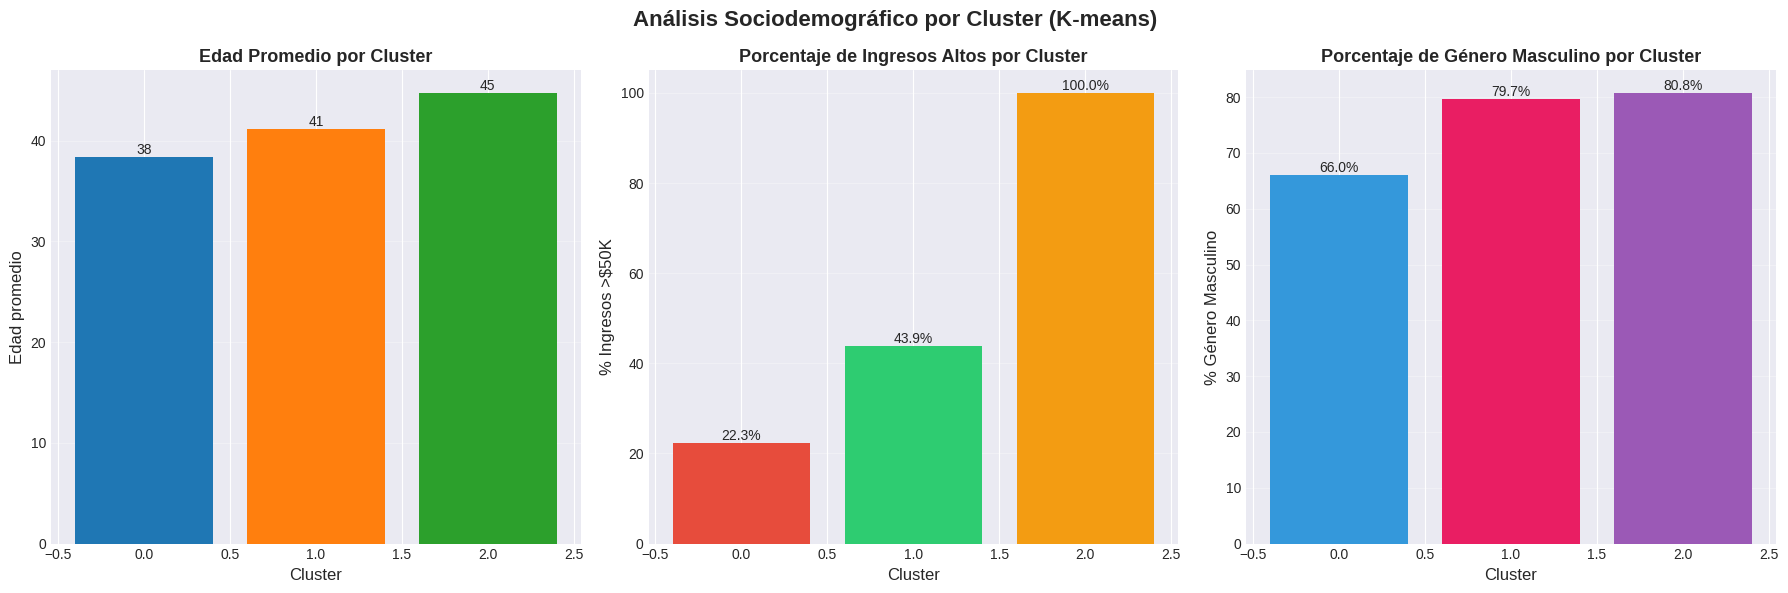

In [4]:
# 1. Gráfico de barras comparativo - Variables sociodemográficas
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Análisis Sociodemográfico por Cluster (K-means)', fontsize=16, fontweight='bold')

# Edad por cluster
age_means = df.groupby('cluster_kmeans')['age'].mean()
bars1 = axes[0].bar(age_means.index, age_means.values, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
axes[0].set_xlabel('Cluster', fontsize=12)
axes[0].set_ylabel('Edad promedio', fontsize=12)
axes[0].set_title('Edad Promedio por Cluster', fontsize=13, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
for bar in bars1:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}',
                ha='center', va='bottom', fontsize=10)

# Porcentaje de ingresos altos por cluster
income_high_pct = df.groupby('cluster_kmeans')['income'].apply(lambda x: (x == '>50K').mean() * 100)
bars2 = axes[1].bar(income_high_pct.index, income_high_pct.values, color=['#e74c3c', '#2ecc71', '#f39c12'])
axes[1].set_xlabel('Cluster', fontsize=12)
axes[1].set_ylabel('% Ingresos >$50K', fontsize=12)
axes[1].set_title('Porcentaje de Ingresos Altos por Cluster', fontsize=13, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
for bar in bars2:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=10)

# Porcentaje de género masculino por cluster
male_pct = df.groupby('cluster_kmeans')['sex'].apply(lambda x: (x == 'Male').mean() * 100)
bars3 = axes[2].bar(male_pct.index, male_pct.values, color=['#3498db', '#e91e63', '#9b59b6'])
axes[2].set_xlabel('Cluster', fontsize=12)
axes[2].set_ylabel('% Género Masculino', fontsize=12)
axes[2].set_title('Porcentaje de Género Masculino por Cluster', fontsize=13, fontweight='bold')
axes[2].grid(axis='y', alpha=0.3)
for bar in bars3:
    height = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


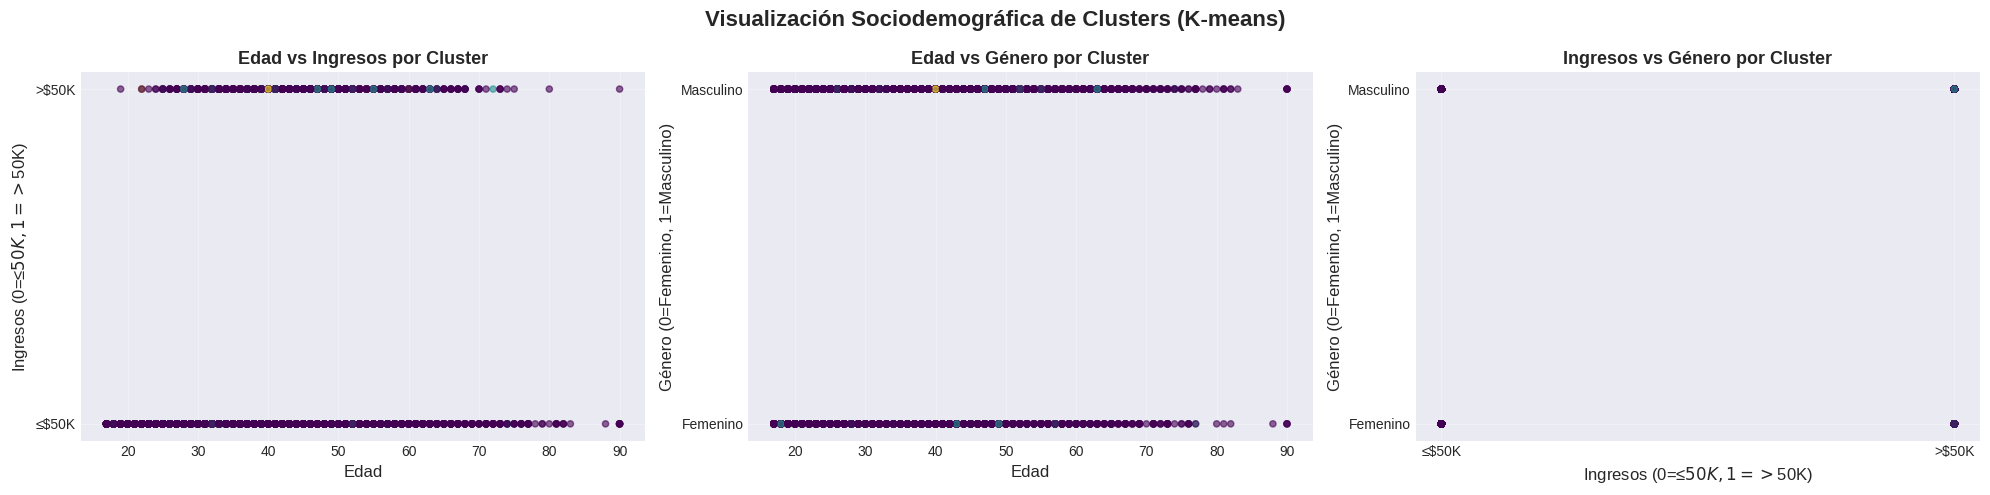

In [ ]:
# 2. Scatter plots - Relaciones sociodemográficas clave
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('Visualización Sociodemográfica de Clusters (K-means)', fontsize=16, fontweight='bold')

# Age vs Income (codificado numéricamente)
df['income_numeric'] = df['income'].map({'<=50K': 0, '>50K': 1})
axes[0].scatter(df['age'], df['income_numeric'], c=df['cluster_kmeans'], 
                cmap='viridis', alpha=0.6, s=20)
axes[0].set_xlabel('Edad', fontsize=12)
axes[0].set_ylabel('Ingresos (0=≤$50K, 1=>$50K)', fontsize=12)
axes[0].set_title('Edad vs Ingresos por Cluster', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(['≤$50K', '>$50K'])


plt.tight_layout()
plt.show()


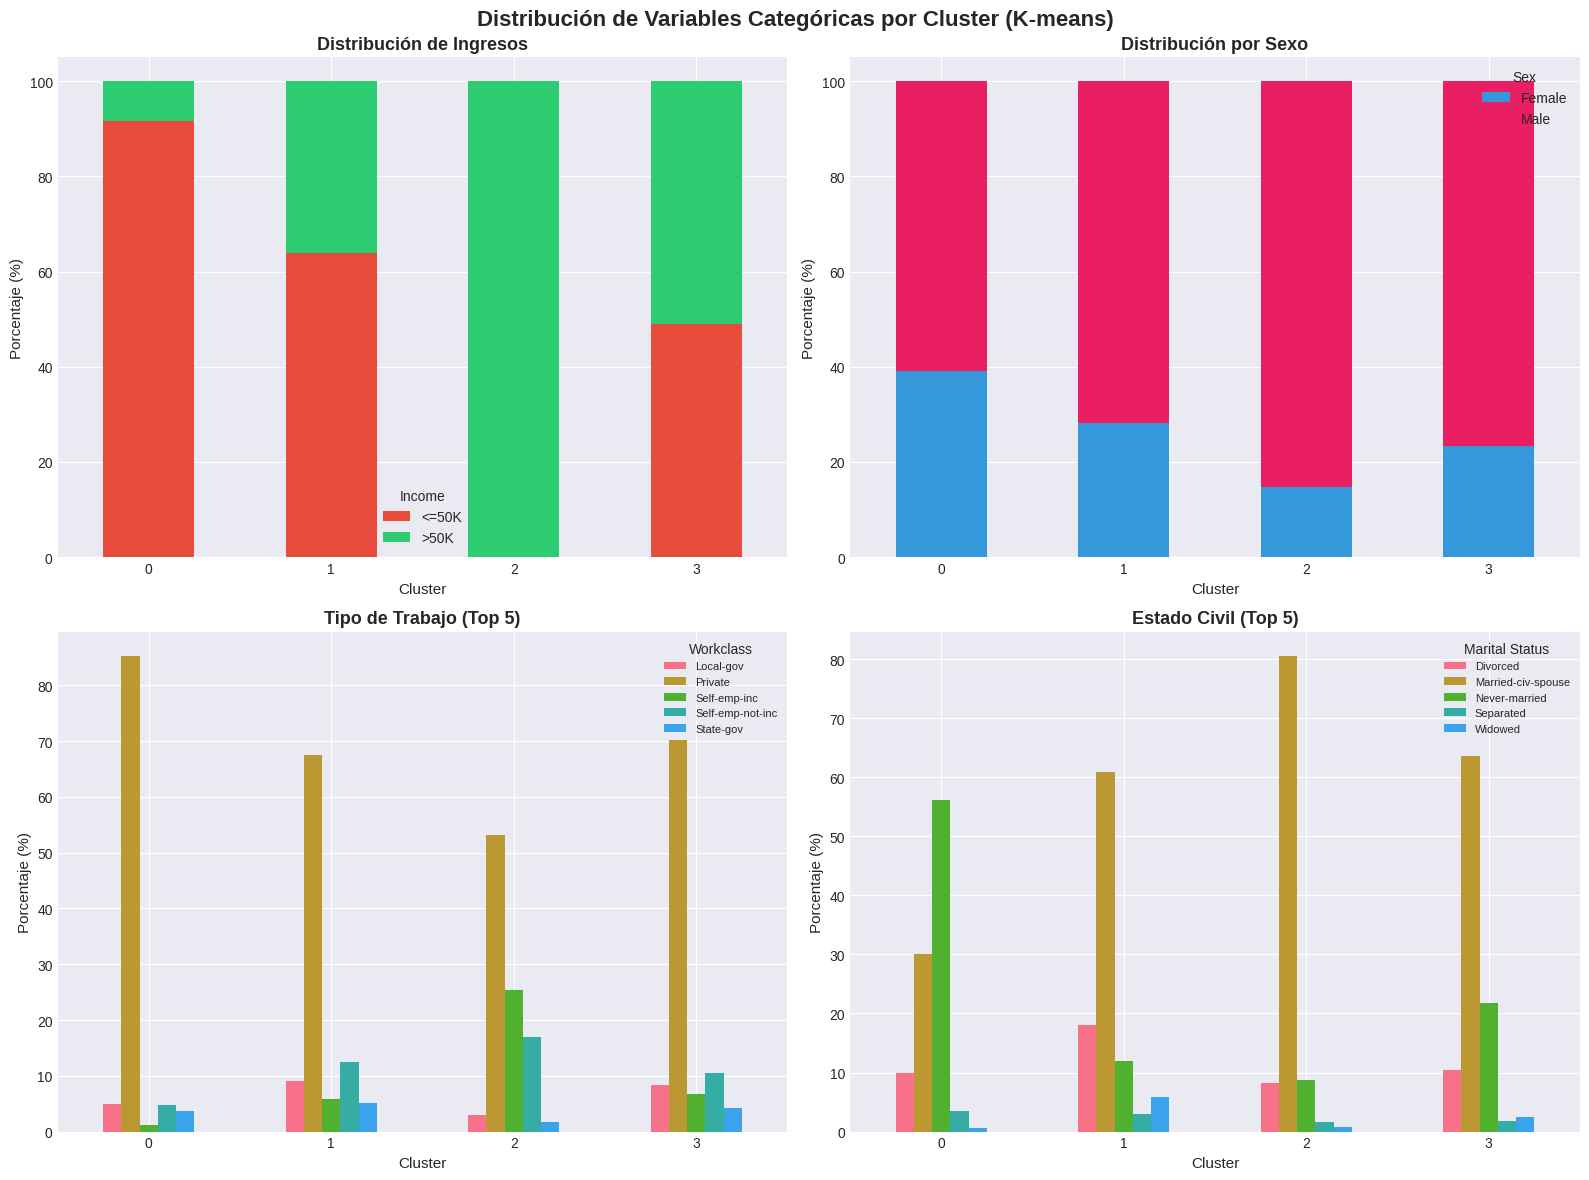

In [ ]:
# 4. Distribución de variables sociodemográficas clave por cluster
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribución de Variables Sociodemográficas por Cluster (K-means)', 
             fontsize=16, fontweight='bold')

# Income
income_counts = pd.crosstab(df['cluster_kmeans'], df['income'], normalize='index') * 100
income_counts.plot(kind='bar', stacked=True, ax=axes[0,0], color=['#e74c3c', '#2ecc71'])
axes[0,0].set_title('Distribución de Ingresos por Cluster', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Cluster', fontsize=11)
axes[0,0].set_ylabel('Porcentaje (%)', fontsize=11)
axes[0,0].legend(title='Ingresos', loc='best')
axes[0,0].set_xticklabels(axes[0,0].get_xticklabels(), rotation=0)

# Sex
sex_counts = pd.crosstab(df['cluster_kmeans'], df['sex'], normalize='index') * 100
sex_counts.plot(kind='bar', stacked=True, ax=axes[0,1], color=['#3498db', '#e91e63'])
axes[0,1].set_title('Distribución por Género por Cluster', fontsize=13, fontweight='bold')
axes[0,1].set_xlabel('Cluster', fontsize=11)
axes[0,1].set_ylabel('Porcentaje (%)', fontsize=11)
axes[0,1].legend(title='Género', loc='best')
axes[0,1].set_xticklabels(axes[0,1].get_xticklabels(), rotation=0)

# Age groups
df['age_group'] = pd.cut(df['age'], bins=[0, 30, 40, 50, 60, 100], 
                        labels=['<30', '30-39', '40-49', '50-59', '60+'])
age_group_counts = pd.crosstab(df['cluster_kmeans'], df['age_group'], normalize='index') * 100
age_group_counts.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Distribución por Grupos de Edad por Cluster', fontsize=13, fontweight='bold')
axes[1,0].set_xlabel('Cluster', fontsize=11)
axes[1,0].set_ylabel('Porcentaje (%)', fontsize=11)
axes[1,0].legend(title='Grupo de Edad', loc='best', fontsize=8)
axes[1,0].set_xticklabels(axes[1,0].get_xticklabels(), rotation=0)

# Income vs Sex combination
income_sex_counts = pd.crosstab([df['cluster_kmeans'], df['income']], df['sex'], normalize='index') * 100
income_sex_counts.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Distribución Ingresos-Género por Cluster', fontsize=13, fontweight='bold')
axes[1,1].set_xlabel('Cluster', fontsize=11)
axes[1,1].set_ylabel('Porcentaje (%)', fontsize=11)
axes[1,1].legend(title='Género', loc='best', fontsize=8)
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()
